# Early stopping vs successive halving after Random Undersampling (RUS)

This notebook asks two questions about CatBoost (`cat`), LightGBM (`lgbm`) and XGBoost
(`xgb`) trained after random undersampling:

1. Does tuning them with **early stopping** (ES) improve their performance compared with
   **successive halving** (SH)?
2. If so, are the boosters trained after RUS now better than the same boosters trained
   on the original (imbalanced) data?

**Tuning schemes**

- **SH**: 100 candidates scored with 10 trees, the best 10 with 300 trees, and the best one
  refit with 800 trees (`functions/cv_undersamplers.py`).
- **ES**: 100 Optuna trials. On each fold, boosting stops when the validation ROC-AUC has
  not improved for 50 rounds, and the best candidate is refit with the mean number of
  rounds at which it stopped (`functions/cv_boosting.py`).

The baseline models (no undersampling) were tuned with SH (successive halving over the
number of trees) or ES in the same way (see `01-analysis-of-ensembles-expanded.ipynb`).

**Datasets**: the 30 datasets where the best baseline model has a ROC-AUC below 0.997.
On the other 7, the models are close to perfect and there is nothing to improve.

The ES models were trained with
`scripts/training_scripts/train-us/train-rus-cnn-early-stopping.py`.

In [1]:
import sys
sys.path.insert(1, '../')

In [2]:
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

from functions.analysis import create_df

## Load results

In [3]:
US = "rus"
boosters = ["cat", "lgbm", "xgb"]


def load(path):
    with open(path, "rb") as f:
        return pickle.load(f)


# test-set results: baseline (no undersampling) and after RUS, tuned with SH or ES
results = {
    "base_sh": load("../models/ensembles/results_previous_tuning"),
    "base_es": load("../models/ensembles/results"),
    "us_sh": load(f"../models/{US}/results"),
    "us_es": load(f"../models/{US}-es/results"),
}

# datasets where the best baseline model has ROC-AUC < 0.997
datasets = list(results["us_es"])
len(datasets)

30

In [4]:
def to_frame(scores, suffix=""):
    """Metrics of the boosters, indexed by (dataset, model)."""
    df = pd.concat(
        [create_df(scores, d, [b + suffix for b in boosters]) for d in datasets],
        keys=datasets,
        names=["dataset", "model"],
    )
    return df.rename(index=lambda m: m.removesuffix(suffix), level="model")


base_sh = to_frame(results["base_sh"])
base_es = to_frame(results["base_es"])
us_sh = to_frame(results["us_sh"], f"_{US}")
us_es = to_frame(results["us_es"], f"_{US}")

In [5]:
def compare(new, ref):
    """
    Per booster and metric: median difference (new - ref) across datasets, number of
    datasets where new is better or worse (higher ROC-AUC and AP, lower Brier score),
    the same counts when the difference is larger than the larger of the two standard
    deviations, and the p-value of a paired Wilcoxon signed-rank test.
    """
    rows = []
    for metric, sign in [("roc", 1), ("ap", 1), ("brier", -1)]:
        for b in boosters:
            n = new.xs(b, level="model")
            r = ref.xs(b, level="model")
            diff = sign * (n[metric] - r[metric])
            std = np.maximum(n[f"{metric}_std"], r[f"{metric}_std"])
            rows.append({
                "metric": metric,
                "model": b,
                "median_diff": (n[metric] - r[metric]).median(),
                "n_better": int((diff > 0).sum()),
                "n_worse": int((diff < 0).sum()),
                "n_better_beyond_std": int((diff > std).sum()),
                "n_worse_beyond_std": int((diff < -std).sum()),
                "wilcoxon_p": wilcoxon(n[metric], r[metric]).pvalue,
            })
    return pd.DataFrame(rows).set_index(["metric", "model"]).round(4)


def roc_table(left, right, names):
    """ROC-AUC (mean ± std) per dataset, with two columns per booster."""
    def mean_std(df):
        return df["roc"].map("{:.3f}".format) + " ± " + df["roc_std"].map("{:.3f}".format)

    return pd.concat(
        {
            b: pd.DataFrame({
                names[0]: mean_std(left.xs(b, level="model")),
                names[1]: mean_std(right.xs(b, level="model")),
            })
            for b in boosters
        },
        axis=1,
    )


def plot_roc(x, y, xlabel, ylabel, filename):
    """Scatter of the ROC-AUC per dataset, one panel per booster."""
    fig, axes = plt.subplots(1, len(boosters), figsize=(4 * len(boosters), 4))
    for ax, b in zip(axes, boosters):
        xs = x.xs(b, level="model")["roc"]
        ys = y.xs(b, level="model")["roc"]
        ax.scatter(xs, ys, s=20, color="steelblue", alpha=0.7)
        lims = [min(xs.min(), ys.min()), max(xs.max(), ys.max())]
        ax.plot(lims, lims, color="navy", linestyle="--")
        ax.set_title(b, fontsize=14)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

## 1. Early stopping vs successive halving after RUS

Differences are ES - SH.

In [6]:
compare(us_es, us_sh)

median_diff  n_better  n_worse  n_better_beyond_std  \
metric model                                                        
roc    cat         0.0062        25        5                    9   
       lgbm        0.0237        24        6                   13   
       xgb         0.0007        17       13                    6   
ap     cat         0.0279        24        6                   12   
       lgbm        0.0298        22        8                   14   
       xgb         0.0047        16       14                    3   
brier  cat        -0.0102        24        6                   16   
       lgbm       -0.0178        23        7                   18   
       xgb        -0.0014        17       13                   12   

              n_worse_beyond_std  wilcoxon_p  
metric model                                  
roc    cat                     1      0.0007  
       lgbm                    2      0.0001  
       xgb                     1      0.9677  
ap     cat                     3      0.0019  
       lgbm                    2      0.0030  
       xgb                     3      0.9515  
brier  cat                     3      0.0062  
       lgbm                    5      0.0013  
       xgb                     8      0.8872

In [7]:
roc_table(us_sh, us_es, ["SH", "ES"])

cat                          lgbm  \
                                           SH             ES             SH   
dataset                                                                       
abalone_19                      0.757 ± 0.114  0.855 ± 0.060  0.718 ± 0.107   
coil_2000                       0.747 ± 0.016  0.753 ± 0.016  0.749 ± 0.013   
ecoli                           0.946 ± 0.031  0.988 ± 0.010  0.746 ± 0.094   
mammography                     0.942 ± 0.011  0.950 ± 0.016  0.939 ± 0.019   
oil                             0.961 ± 0.012  0.961 ± 0.005  0.891 ± 0.029   
ozone_level                     0.842 ± 0.048  0.862 ± 0.049  0.830 ± 0.035   
protein_homo                    0.994 ± 0.001  0.994 ± 0.001  0.995 ± 0.001   
satimage                        0.963 ± 0.003  0.964 ± 0.004  0.965 ± 0.005   
scene                           0.757 ± 0.040  0.759 ± 0.050  0.757 ± 0.041   
sick_euthyroid                  0.978 ± 0.015  0.982 ± 0.012  0.980 ± 0.013   
solar_flare_m0                  0.829 ± 0.029  0.879 ± 0.049  0.834 ± 0.035   
spectrometer                    0.988 ± 0.006  0.992 ± 0.005  0.994 ± 0.003   
thyroid_sick                    0.990 ± 0.003  0.985 ± 0.005  0.977 ± 0.002   
us_crime                        0.927 ± 0.021  0.934 ± 0.016  0.931 ± 0.018   
webpage                         0.979 ± 0.004  0.985 ± 0.004  0.959 ± 0.007   
wine_quality                    0.819 ± 0.019  0.816 ± 0.018  0.788 ± 0.015   
yeast_me2                       0.904 ± 0.042  0.911 ± 0.039  0.886 ± 0.075   
cleveland-0_vs_4                0.949 ± 0.056  0.990 ± 0.018  0.500 ± 0.000   
glass-0-1-4-6_vs_2              0.876 ± 0.160  0.719 ± 0.248  0.500 ± 0.000   
led7digit-0-2-4-5-6-7-8-9_vs_1  0.946 ± 0.031  0.952 ± 0.017  0.898 ± 0.042   
pima                            0.820 ± 0.029  0.833 ± 0.033  0.758 ± 0.045   
poker-8-9_vs_5                  0.597 ± 0.095  0.547 ± 0.083  0.500 ± 0.000   
diabetes130                     0.644 ± 0.007  0.673 ± 0.006  0.665 ± 0.009   
default_credit                  0.748 ± 0.009  0.777 ± 0.006  0.748 ± 0.006   
htru2                           0.971 ± 0.006  0.976 ± 0.006  0.969 ± 0.004   
credit_fraud                    0.977 ± 0.007  0.980 ± 0.009  0.977 ± 0.007   
secom                           0.682 ± 0.058  0.776 ± 0.056  0.721 ± 0.027   
bank-marketing                  0.923 ± 0.003  0.929 ± 0.004  0.922 ± 0.003   
telco                           0.815 ± 0.017  0.843 ± 0.014  0.805 ± 0.015   
adult                           0.914 ± 0.003  0.927 ± 0.001  0.901 ± 0.003   

                                                         xgb                 
                                           ES             SH             ES  
dataset                                                                      
abalone_19                      0.753 ± 0.099  0.853 ± 0.080  0.807 ± 0.100  
coil_2000                       0.740 ± 0.022  0.752 ± 0.015  0.755 ± 0.017  
ecoli                           0.976 ± 0.017  0.887 ± 0.043  0.905 ± 0.051  
mammography                     0.928 ± 0.014  0.948 ± 0.015  0.948 ± 0.016  
oil                             0.936 ± 0.014  0.936 ± 0.010  0.942 ± 0.021  
ozone_level                     0.834 ± 0.043  0.853 ± 0.031  0.811 ± 0.052  
protein_homo                    0.994 ± 0.001  0.994 ± 0.001  0.995 ± 0.000  
satimage                        0.970 ± 0.004  0.963 ± 0.003  0.967 ± 0.003  
scene                           0.778 ± 0.033  0.757 ± 0.042  0.744 ± 0.043  
sick_euthyroid                  0.985 ± 0.009  0.984 ± 0.007  0.985 ± 0.009  
solar_flare_m0                  0.845 ± 0.036  0.872 ± 0.044  0.848 ± 0.044  
spectrometer                    0.984 ± 0.010  0.992 ± 0.006  0.989 ± 0.006  
thyroid_sick                    0.974 ± 0.003  0.976 ± 0.003  0.982 ± 0.003  
us_crime                        0.914 ± 0.021  0.936 ± 0.016  0.924 ± 0.015  
webpage                         0.985 ± 0.003  0.980 ± 0.004  0.979 ± 0.005  
wine_quality                  

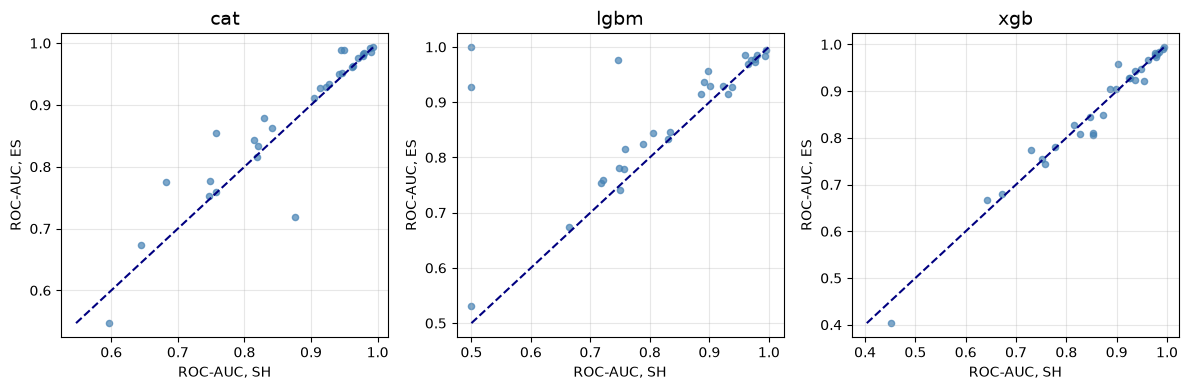

In [8]:
plot_roc(us_sh, us_es, "ROC-AUC, SH", "ROC-AUC, ES", f"../figures/{US}_expanded_es_vs_sh.png")

### Conclusion: ES vs SH after RUS

Early stopping improves `cat` and `lgbm` after RUS on all three metrics:

- **`cat`**: ROC-AUC median +0.006, better on 25 of 30 datasets (p < 0.001). AP and Brier score improve as well.
- **`lgbm`**: ROC-AUC median +0.024, better on 24 of 30 datasets (p < 0.001). The largest gains are on small datasets where `lgbm` tuned with SH broke down (`cleveland-0_vs_4` +0.50, `glass-0-1-4-6_vs_2` +0.43, `ecoli` +0.23).
- **`xgb`**: no change (p = 0.97 for ROC-AUC).

SH refit every model with 800 trees, which overfits the small training sets left after RUS. Early stopping adapts the number of rounds to the data.

## 2. RUS vs no undersampling

Differences are RUS - no undersampling, with both tuned with early stopping.

In [9]:
compare(us_es, base_es)

median_diff  n_better  n_worse  n_better_beyond_std  \
metric model                                                        
roc    cat        -0.0013        13       17                    1   
       lgbm       -0.0069         5       25                    1   
       xgb        -0.0106         4       26                    0   
ap     cat        -0.0186         9       21                    1   
       lgbm       -0.0362         4       26                    1   
       xgb        -0.0484         5       25                    0   
brier  cat         0.0559         0       30                    0   
       lgbm        0.0535         2       28                    0   
       xgb         0.0855         0       30                    0   

              n_worse_beyond_std  wilcoxon_p  
metric model                                  
roc    cat                     9      0.6850  
       lgbm                   12      0.0015  
       xgb                    12      0.0000  
ap     cat                    12      0.0040  
       lgbm                   14      0.0003  
       xgb                    14      0.0000  
brier  cat                    29      0.0000  
       lgbm                   27      0.0000  
       xgb                    29      0.0000

In [10]:
roc_table(base_es, us_es, ["no US", "RUS"])

cat                          lgbm  \
                                        no US            RUS          no US   
dataset                                                                       
abalone_19                      0.862 ± 0.046  0.855 ± 0.060  0.854 ± 0.062   
coil_2000                       0.768 ± 0.017  0.753 ± 0.016  0.773 ± 0.012   
ecoli                           0.973 ± 0.022  0.988 ± 0.010  0.983 ± 0.013   
mammography                     0.941 ± 0.013  0.950 ± 0.016  0.958 ± 0.011   
oil                             0.971 ± 0.009  0.961 ± 0.005  0.946 ± 0.007   
ozone_level                     0.830 ± 0.069  0.862 ± 0.049  0.847 ± 0.046   
protein_homo                    0.995 ± 0.001  0.994 ± 0.001  0.995 ± 0.001   
satimage                        0.974 ± 0.002  0.964 ± 0.004  0.975 ± 0.004   
scene                           0.802 ± 0.034  0.759 ± 0.050  0.802 ± 0.016   
sick_euthyroid                  0.987 ± 0.010  0.982 ± 0.012  0.986 ± 0.010   
solar_flare_m0                  0.874 ± 0.059  0.879 ± 0.049  0.880 ± 0.051   
spectrometer                    0.994 ± 0.005  0.992 ± 0.005  0.978 ± 0.013   
thyroid_sick                    0.993 ± 0.002  0.985 ± 0.005  0.981 ± 0.006   
us_crime                        0.932 ± 0.023  0.934 ± 0.016  0.911 ± 0.026   
webpage                         0.983 ± 0.006  0.985 ± 0.004  0.990 ± 0.004   
wine_quality                    0.852 ± 0.017  0.816 ± 0.018  0.845 ± 0.012   
yeast_me2                       0.889 ± 0.053  0.911 ± 0.039  0.928 ± 0.017   
cleveland-0_vs_4                0.871 ± 0.125  0.990 ± 0.018  0.924 ± 0.062   
glass-0-1-4-6_vs_2              0.732 ± 0.209  0.719 ± 0.248  0.735 ± 0.198   
led7digit-0-2-4-5-6-7-8-9_vs_1  0.924 ± 0.030  0.952 ± 0.017  0.963 ± 0.014   
pima                            0.832 ± 0.029  0.833 ± 0.033  0.827 ± 0.039   
poker-8-9_vs_5                  0.897 ± 0.048  0.547 ± 0.083  0.873 ± 0.058   
diabetes130                     0.680 ± 0.006  0.673 ± 0.006  0.685 ± 0.007   
default_credit                  0.778 ± 0.007  0.777 ± 0.006  0.777 ± 0.005   
htru2                           0.975 ± 0.007  0.976 ± 0.006  0.977 ± 0.005   
credit_fraud                    0.968 ± 0.011  0.980 ± 0.009  0.980 ± 0.007   
secom                           0.754 ± 0.042  0.776 ± 0.056  0.771 ± 0.058   
bank-marketing                  0.934 ± 0.003  0.929 ± 0.004  0.933 ± 0.003   
telco                           0.845 ± 0.014  0.843 ± 0.014  0.844 ± 0.014   
adult                           0.929 ± 0.001  0.927 ± 0.001  0.931 ± 0.001   

                                                         xgb                 
                                          RUS          no US            RUS  
dataset                                                                      
abalone_19                      0.753 ± 0.099  0.834 ± 0.069  0.807 ± 0.100  
coil_2000                       0.740 ± 0.022  0.778 ± 0.013  0.755 ± 0.017  
ecoli                           0.976 ± 0.017  0.975 ± 0.022  0.905 ± 0.051  
mammography                     0.928 ± 0.014  0.945 ± 0.015  0.948 ± 0.016  
oil                             0.936 ± 0.014  0.957 ± 0.010  0.942 ± 0.021  
ozone_level                     0.834 ± 0.043  0.896 ± 0.035  0.811 ± 0.052  
protein_homo                    0.994 ± 0.001  0.996 ± 0.000  0.995 ± 0.000  
satimage                        0.970 ± 0.004  0.977 ± 0.003  0.967 ± 0.003  
scene                           0.778 ± 0.033  0.804 ± 0.033  0.744 ± 0.043  
sick_euthyroid                  0.985 ± 0.009  0.986 ± 0.011  0.985 ± 0.009  
solar_flare_m0                  0.845 ± 0.036  0.871 ± 0.065  0.848 ± 0.044  
spectrometer                    0.984 ± 0.010  0.995 ± 0.004  0.989 ± 0.006  
thyroid_sick                    0.974 ± 0.003  0.994 ± 0.002  0.982 ± 0.003  
us_crime                        0.914 ± 0.021  0.937 ± 0.013  0.924 ± 0.015  
webpage                         0.985 ± 0.003  0.980 ± 0.006  0.979 ± 0.005  
wine_quality                  

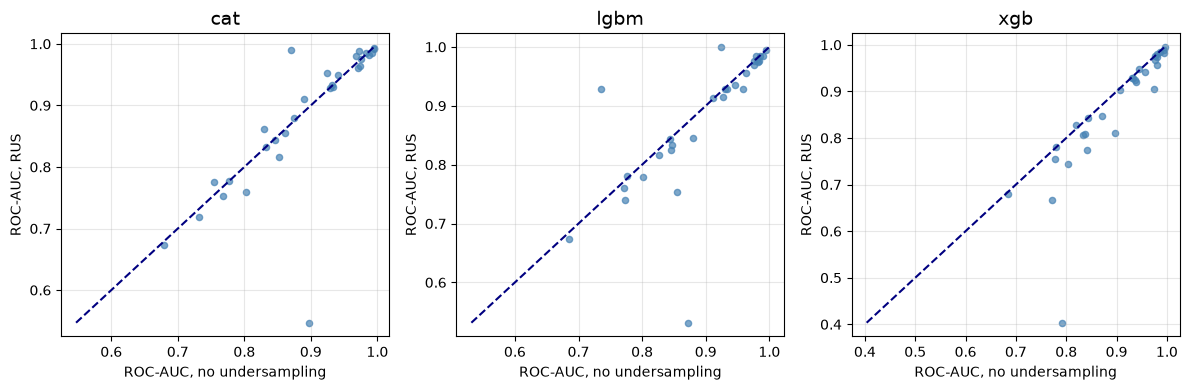

In [11]:
plot_roc(base_es, us_es, "ROC-AUC, no undersampling", "ROC-AUC, RUS", f"../figures/{US}_expanded_vs_no_us.png")

For reference, the same comparison with both tuned with successive halving (RUS - no undersampling):

In [12]:
compare(us_sh, base_sh)

median_diff  n_better  n_worse  n_better_beyond_std  \
metric model                                                        
roc    cat        -0.0058         7       23                    0   
       lgbm       -0.0182         5       25                    0   
       xgb        -0.0063         5       25                    0   
ap     cat        -0.0539         6       24                    1   
       lgbm       -0.0985         2       28                    0   
       xgb        -0.0365         4       26                    1   
brier  cat         0.0593         0       30                    0   
       lgbm        0.0914         0       30                    0   
       xgb         0.0536         0       30                    0   

              n_worse_beyond_std  wilcoxon_p  
metric model                                  
roc    cat                     9      0.0022  
       lgbm                   15      0.0000  
       xgb                    14      0.0022  
ap     cat                    17      0.0008  
       lgbm                   22      0.0000  
       xgb                    14      0.0000  
brier  cat                    26      0.0000  
       lgbm                   29      0.0000  
       xgb                    28      0.0000

### Conclusion: RUS vs no undersampling

Even with early stopping, the boosters trained after RUS are not better than the boosters trained on the original data:

- **`lgbm`** and **`xgb`** are worse on ROC-AUC on 25–26 of 30 datasets (p ≤ 0.002), and worse on AP.
- **`cat`** has the same ROC-AUC as without RUS (p = 0.69, better on 13 datasets, worse on 17), but a lower AP (p = 0.004).
- No booster is better after RUS by more than the standard deviation on more than 1 dataset.
- The Brier score is worse on almost all datasets, as expected: RUS shifts the predicted probabilities towards the minority class.

Early stopping narrows the gap for `cat` (median ROC-AUC difference -0.006 with SH, -0.001 with ES) and `lgbm` (-0.018 to -0.007), but does not close it.

## Conclusions

1. Limiting the boosting rounds with early stopping improves CatBoost and LightGBM trained after RUS, compared with successive halving. XGBoost does not change.
2. Even so, RUS does not make the boosters better than the same boosters trained on the imbalanced data. At best (`cat`), they match the ROC-AUC but have a lower AP and worse calibrated probabilities.